In [4]:

# ============================================================
# BLOQUE 1 - CONFIGURACIÓN Y CARGA DE CARPETA
# ============================================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import base64

from pathlib import Path
from IPython.display import display, HTML
from google.colab import output

# Crear estructura del proyecto
PROYECTO = Path("/content/Proyecto_Pyraminx")
CARPETA_IMAGENES = PROYECTO / "imagenes"
CARPETA_RESULTADOS = PROYECTO / "resultados"

CARPETA_IMAGENES.mkdir(parents=True, exist_ok=True)
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

EXTENSIONES = {".jpg", ".jpeg", ".png", ".webp",
               ".bmp", ".tif", ".tiff"}

# Limpiar imágenes de cargas anteriores
for archivo in CARPETA_IMAGENES.rglob("*"):
    if archivo.is_file() and archivo.suffix.lower() in EXTENSIONES:
        archivo.unlink()

# Recibir fragmentos de archivos desde el navegador
def recibir_fragmento(ruta_relativa, contenido_base64, primero):
    partes = ruta_relativa.replace("\\", "/").split("/")

    if len(partes) < 2 or any(
        parte in ("", ".", "..") for parte in partes
    ):
        raise ValueError("Ruta de archivo no permitida")

    destino = CARPETA_IMAGENES.joinpath(*partes[1:])

    if destino.suffix.lower() not in EXTENSIONES:
        return

    destino.parent.mkdir(parents=True, exist_ok=True)

    modo = "wb" if primero else "ab"

    with open(destino, modo) as archivo:
        archivo.write(base64.b64decode(contenido_base64))

output.register_callback(
    "pyraminx.recibir_fragmento",
    recibir_fragmento
)

# Selector de carpeta desde el computador
display(HTML("""
<div style="padding:15px;border:1px solid #bbb;border-radius:8px">
  <h3>Cargar fotografías del Pyraminx</h3>
  <p>Selecciona la carpeta que contiene las cinco fotografías.</p>
  <input type="file" id="carpeta_pyraminx"
         webkitdirectory directory multiple>
  <p id="estado_pyraminx">Esperando selección...</p>
</div>

<script>
const selector = document.getElementById("carpeta_pyraminx");
const estado = document.getElementById("estado_pyraminx");

selector.addEventListener("change", async function() {
  const archivos = [...selector.files].filter(f =>
    /\\.(jpg|jpeg|png|webp|bmp|tif|tiff)$/i.test(f.name)
  );

  if (!archivos.length) {
    estado.textContent = "No se encontraron imágenes.";
    return;
  }

  selector.disabled = true;

  try {
    let procesados = 0;

    for (const archivo of archivos) {
      const tamanoBloque = 768 * 1024;
      const partes = Math.max(
        1, Math.ceil(archivo.size / tamanoBloque)
      );

      for (let i = 0; i < partes; i++) {
        const fragmento = archivo.slice(
          i * tamanoBloque,
          (i + 1) * tamanoBloque
        );

        const base64 = await new Promise((resolve, reject) => {
          const lector = new FileReader();

          lector.onload = () =>
            resolve(lector.result.split(",")[1]);

          lector.onerror = reject;
          lector.readAsDataURL(fragmento);
        });

        await google.colab.kernel.invokeFunction(
          "pyraminx.recibir_fragmento",
          [archivo.webkitRelativePath, base64, i === 0],
          {}
        );
      }

      procesados++;
      estado.textContent =
        "Subidas " + procesados + " de " +
        archivos.length + " imágenes.";
    }

    estado.textContent =
      "Carga completa: " + procesados + " imágenes.";

  } catch (error) {
    estado.textContent = "Error en la carga: " + error.message;
    console.error(error);
  } finally {
    selector.disabled = false;
  }
});
</script>
"""))

print("Carpeta de entrada:", CARPETA_IMAGENES)
print("Carpeta de resultados:", CARPETA_RESULTADOS)


Carpeta de entrada: /content/Proyecto_Pyraminx/imagenes
Carpeta de resultados: /content/Proyecto_Pyraminx/resultados


In [12]:

# ============================================================
# BLOQUE 2 - VERIFICACIÓN Y CLASIFICACIÓN
# ============================================================

archivos = sorted(
    [
        p for p in CARPETA_IMAGENES.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTENSIONES
    ],
    key=lambda p: p.name.lower()
)

print("IMÁGENES ENCONTRADAS:", len(archivos))

for i, ruta in enumerate(archivos, 1):
    print(f"{i}. {ruta.name}")

if len(archivos) != 5:
    raise ValueError(
        "Se necesitan exactamente cinco fotografías. "
        "Verifica la carpeta cargada."
    )

# Orden de las fotografías según su condición.
# Si el orden impreso anteriormente es diferente,
# modifica los números de esta lista.

ORDEN_ARCHIVOS = [0, 2, 3, 1, 4]

CONDICIONES = [
    "Movimiento",
    "Sobreexposición",
    "Subexposición",
    "Referencia",
    "Desenfoque"
]

FOTOS = {}

for condicion, indice in zip(CONDICIONES, ORDEN_ARCHIVOS):
    ruta = archivos[indice]
    imagen = cv2.imread(str(ruta), cv2.IMREAD_COLOR)

    if imagen is None:
        raise ValueError(f"No se pudo leer: {ruta.name}")

    FOTOS[condicion] = {
        "ruta": ruta,
        "imagen": imagen
    }

print("\nCLASIFICACIÓN FINAL:")
for condicion, datos in FOTOS.items():
    alto, ancho = datos["imagen"].shape[:2]
    print(
        f"{condicion}: {datos['ruta'].name} "
        f"({ancho} x {alto} píxeles)"
    )


IMÁGENES ENCONTRADAS: 5
1. WhatsApp-Image-2026-10-12-at-10.34.26-PM.png
2. WhatsApp-Image-2026-10-12-at-10.34.33-PM-_1_.png
3. WhatsApp-Image-2026-10-12-at-10.34.33-PM-_2_.png
4. WhatsApp-Image-2026-10-12-at-10.34.33-PM.png
5. WhatsApp-Image-2026-10-12-at-10.37.28-PM.png

CLASIFICACIÓN FINAL:
Movimiento: WhatsApp-Image-2026-10-12-at-10.34.26-PM.png (1600 x 1200 píxeles)
Sobreexposición: WhatsApp-Image-2026-10-12-at-10.34.33-PM-_2_.png (1200 x 1600 píxeles)
Subexposición: WhatsApp-Image-2026-10-12-at-10.34.33-PM.png (1200 x 1600 píxeles)
Referencia: WhatsApp-Image-2026-10-12-at-10.34.33-PM-_1_.png (1200 x 1600 píxeles)
Desenfoque: WhatsApp-Image-2026-10-12-at-10.37.28-PM.png (1174 x 1600 píxeles)


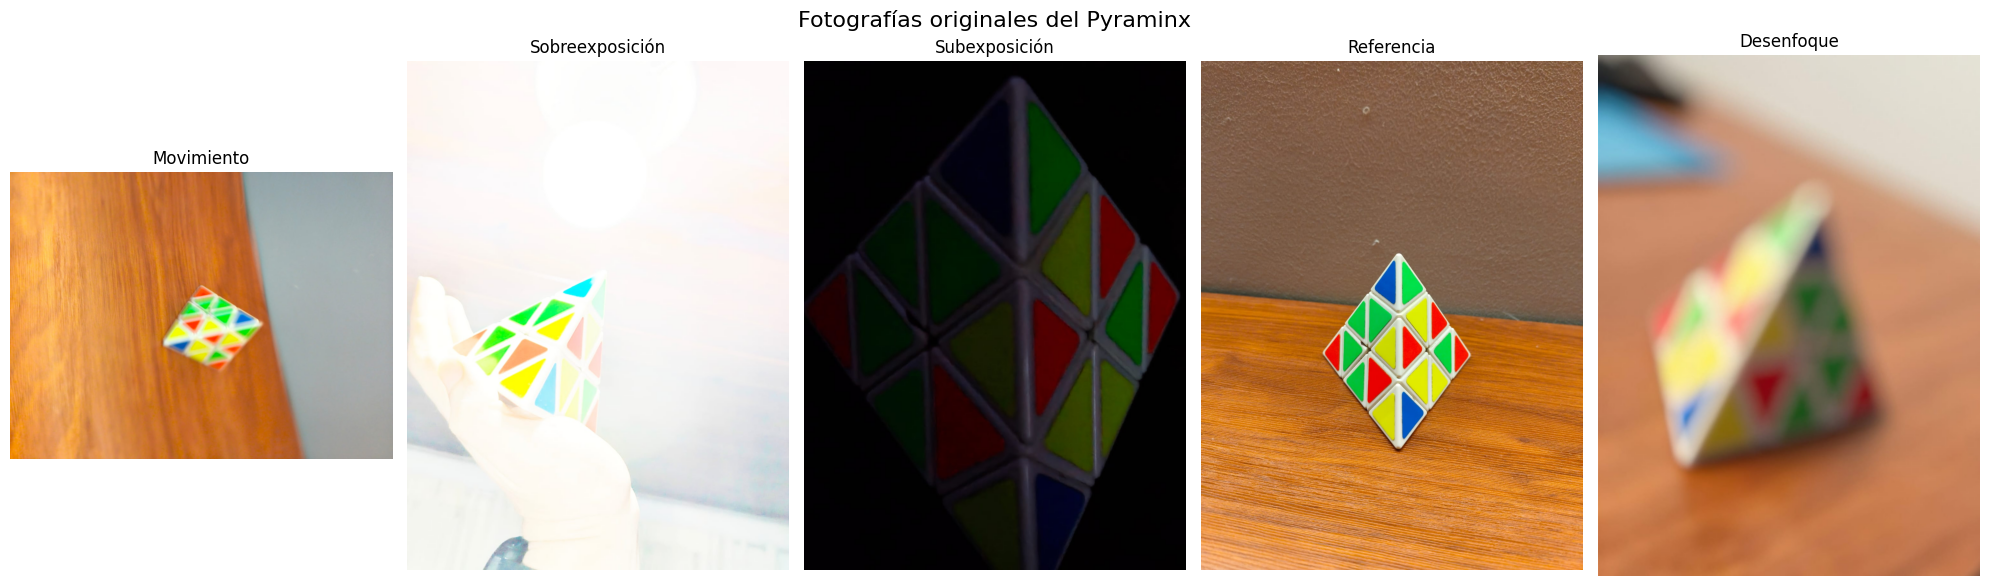

In [13]:

# ============================================================
# BLOQUE 3 - VISUALIZACIÓN DEL CONJUNTO ORIGINAL
# ============================================================

fig, ejes = plt.subplots(1, 5, figsize=(20, 6))

for eje, (condicion, datos) in zip(ejes, FOTOS.items()):

    imagen_rgb = cv2.cvtColor(
        datos["imagen"],
        cv2.COLOR_BGR2RGB
    )

    eje.imshow(imagen_rgb)
    eje.set_title(condicion, fontsize=12)
    eje.axis("off")

plt.suptitle(
    "Fotografías originales del Pyraminx",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    CARPETA_RESULTADOS / "01_imagenes_originales.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [14]:

# ============================================================
# BLOQUE 4 - DIAGNÓSTICO CUANTITATIVO
# ============================================================

def calcular_metricas(imagen):

    gris = cv2.cvtColor(
        imagen,
        cv2.COLOR_BGR2GRAY
    )

    brillo = np.mean(gris)
    contraste = np.std(gris)

    porcentaje_oscuros = (
        np.mean(gris <= 20) * 100
    )

    porcentaje_claros = (
        np.mean(gris >= 245) * 100
    )

    laplaciano = cv2.Laplacian(
        gris,
        cv2.CV_64F
    )

    nitidez = np.var(laplaciano)

    histograma = cv2.calcHist(
        [gris], [0], None, [256], [0, 256]
    ).ravel()

    probabilidades = histograma / histograma.sum()
    probabilidades = probabilidades[
        probabilidades > 0
    ]

    entropia = -np.sum(
        probabilidades * np.log2(probabilidades)
    )

    return {
        "Brillo medio": round(float(brillo), 2),
        "Contraste (desv. estándar)": round(
            float(contraste), 2
        ),
        "Píxeles oscuros (%)": round(
            float(porcentaje_oscuros), 2
        ),
        "Píxeles claros (%)": round(
            float(porcentaje_claros), 2
        ),
        "Varianza del Laplaciano": round(
            float(nitidez), 2
        ),
        "Entropía (bits)": round(
            float(entropia), 3
        )
    }


registros = []

for condicion, datos in FOTOS.items():

    metricas = calcular_metricas(datos["imagen"])

    registro = {
        "Condición": condicion,
        "Archivo": datos["ruta"].name,
        **metricas
    }

    registros.append(registro)

tabla_diagnostico = pd.DataFrame(registros)

display(tabla_diagnostico)

tabla_diagnostico.to_csv(
    CARPETA_RESULTADOS / "02_diagnostico.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Diagnóstico guardado correctamente.")
print(
    "Nota: las medidas son globales e incluyen el fondo. "
    "La varianza del Laplaciano no equivale directamente "
    "a una puntuación absoluta de calidad."
)


,Condición,Archivo,Brillo medio,Contraste (desv. estándar),Píxeles oscuros (%),Píxeles claros (%),Varianza del Laplaciano,Entropía (bits)
0,Movimiento,WhatsApp-Image-2026-10-12-at-10.34.26-PM.png,155.17,25.42,0.00,0.06,8.58,6.383
1,Sobreexposición,WhatsApp-Image-2026-10-12-at-10.34.33-PM-_2_.png,244.24,12.78,0.00,69.33,1.80,4.713
2,Subexposición,WhatsApp-Image-2026-10-12-at-10.34.33-PM.png,13.95,17.43,73.55,0.00,1.25,4.167
3,Referencia,WhatsApp-Image-2026-10-12-at-10.34.33-PM-_1_.png,122.11,30.90,0.00,0.07,600.20,6.523
4,Desenfoque,WhatsApp-Image-2026-10-12-at-10.37.28-PM.png,153.57,42.77,0.00,0.00,1.15,7.000


Diagnóstico guardado correctamente.
Nota: las medidas son globales e incluyen el fondo. La varianza del Laplaciano no equivale directamente a una puntuación absoluta de calidad.


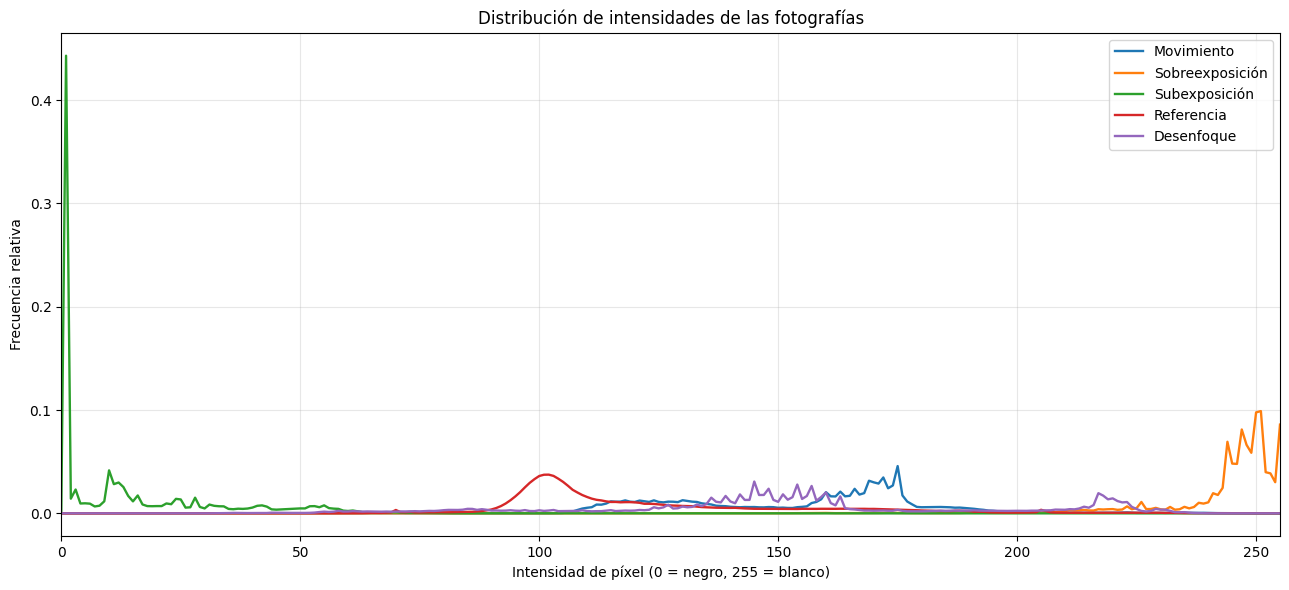

In [15]:

# ============================================================
# BLOQUE 5 - HISTOGRAMAS DE LAS CINCO FOTOGRAFÍAS
# ============================================================

plt.figure(figsize=(13, 6))

for condicion, datos in FOTOS.items():

    gris = cv2.cvtColor(
        datos["imagen"],
        cv2.COLOR_BGR2GRAY
    )

    histograma = cv2.calcHist(
        [gris],
        [0],
        None,
        [256],
        [0, 256]
    ).ravel()

    # Normalización para comparar distintas resoluciones
    histograma = histograma / histograma.sum()

    plt.plot(
        histograma,
        label=condicion,
        linewidth=1.7
    )

plt.title("Distribución de intensidades de las fotografías")
plt.xlabel("Intensidad de píxel (0 = negro, 255 = blanco)")
plt.ylabel("Frecuencia relativa")
plt.xlim(0, 255)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    CARPETA_RESULTADOS / "03_histogramas_originales.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


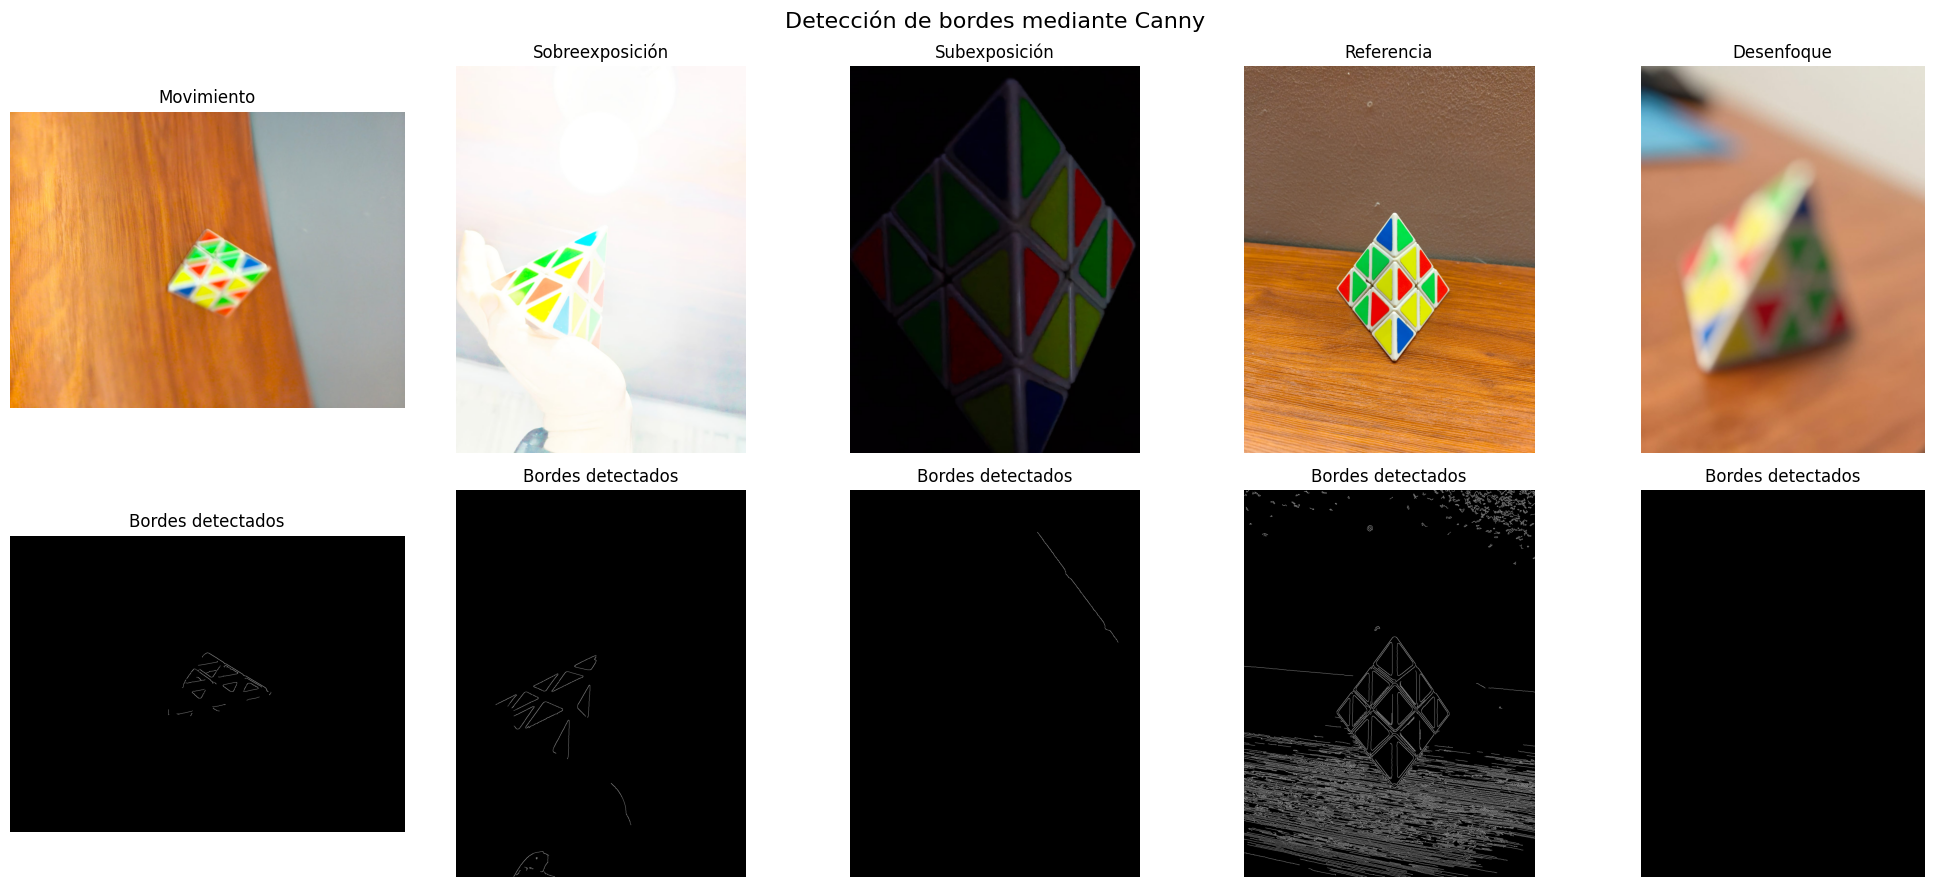

,Condición,Densidad de bordes (%)
0,Movimiento,0.111
1,Sobreexposición,0.199
2,Subexposición,0.039
3,Referencia,7.588
4,Desenfoque,0.000


In [16]:

# ============================================================
# BLOQUE 6 - DETECCIÓN DE BORDES CON CANNY
# ============================================================

fig, ejes = plt.subplots(2, 5, figsize=(20, 9))

resultados_bordes = []

for i, (condicion, datos) in enumerate(FOTOS.items()):

    imagen = datos["imagen"]

    gris = cv2.cvtColor(
        imagen,
        cv2.COLOR_BGR2GRAY
    )

    suavizada = cv2.GaussianBlur(
        gris, (5, 5), 0
    )

    bordes = cv2.Canny(
        suavizada,
        threshold1=40,
        threshold2=110
    )

    imagen_rgb = cv2.cvtColor(
        imagen,
        cv2.COLOR_BGR2RGB
    )

    ejes[0, i].imshow(imagen_rgb)
    ejes[0, i].set_title(condicion)
    ejes[0, i].axis("off")

    ejes[1, i].imshow(
        bordes,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    ejes[1, i].set_title("Bordes detectados")
    ejes[1, i].axis("off")

    densidad = np.mean(bordes > 0) * 100

    resultados_bordes.append({
        "Condición": condicion,
        "Densidad de bordes (%)": round(
            float(densidad), 3
        )
    })

    cv2.imwrite(
        str(
            CARPETA_RESULTADOS /
            f"bordes_{i+1:02d}.png"
        ),
        bordes
    )

plt.suptitle(
    "Detección de bordes mediante Canny",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    CARPETA_RESULTADOS / "04_comparacion_bordes.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

tabla_bordes = pd.DataFrame(resultados_bordes)
display(tabla_bordes)

tabla_bordes.to_csv(
    CARPETA_RESULTADOS / "04_metricas_bordes.csv",
    index=False
)


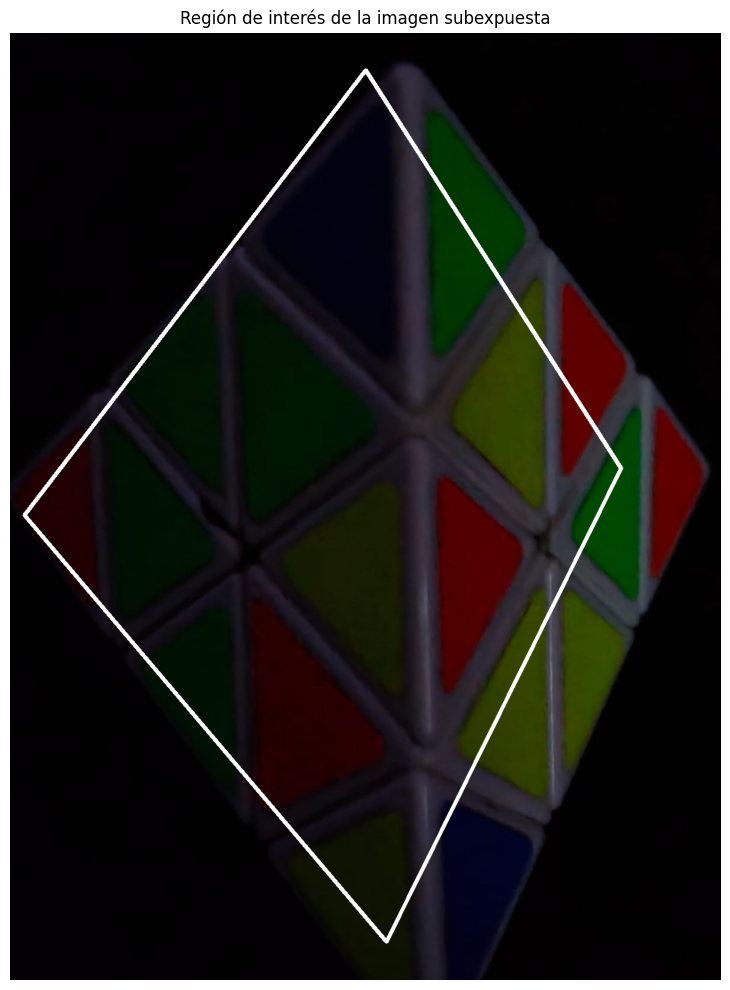

Dimensiones: 1200 x 1600
Píxeles incluidos en la región: 718905


In [17]:

# ============================================================
# BLOQUE 7 - SELECCIÓN DE IMAGEN Y REGIÓN DE INTERÉS
# ============================================================

imagen_original = FOTOS["Subexposición"]["imagen"].copy()

alto, ancho = imagen_original.shape[:2]

# Coordenadas relativas (x, y), entre 0 y 1.
# Ajustar si el polígono no cubre la región deseada.

POLIGONO_RELATIVO = np.array([
    [0.50, 0.04],  # Vértice superior
    [0.86, 0.46],  # Vértice derecho
    [0.53, 0.96],  # Vértice inferior
    [0.02, 0.51]   # Vértice izquierdo
], dtype=np.float32)

poligono = np.rint(
    POLIGONO_RELATIVO *
    np.array([ancho - 1, alto - 1])
).astype(np.int32)

mascara_roi = np.zeros(
    (alto, ancho),
    dtype=np.uint8
)

cv2.fillPoly(
    mascara_roi,
    [poligono],
    255
)

# Reducir ligeramente los bordes de la máscara
mascara_roi = cv2.erode(
    mascara_roi,
    np.ones((11, 11), np.uint8),
    iterations=1
)

visualizacion = cv2.cvtColor(
    imagen_original,
    cv2.COLOR_BGR2RGB
).copy()

cv2.polylines(
    visualizacion,
    [poligono],
    True,
    (255, 255, 255),
    5
)

plt.figure(figsize=(8, 10))
plt.imshow(visualizacion)
plt.title("Región de interés de la imagen subexpuesta")
plt.axis("off")
plt.tight_layout()

plt.savefig(
    CARPETA_RESULTADOS / "05_region_interes.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Dimensiones:", ancho, "x", alto)
print(
    "Píxeles incluidos en la región:",
    np.count_nonzero(mascara_roi)
)


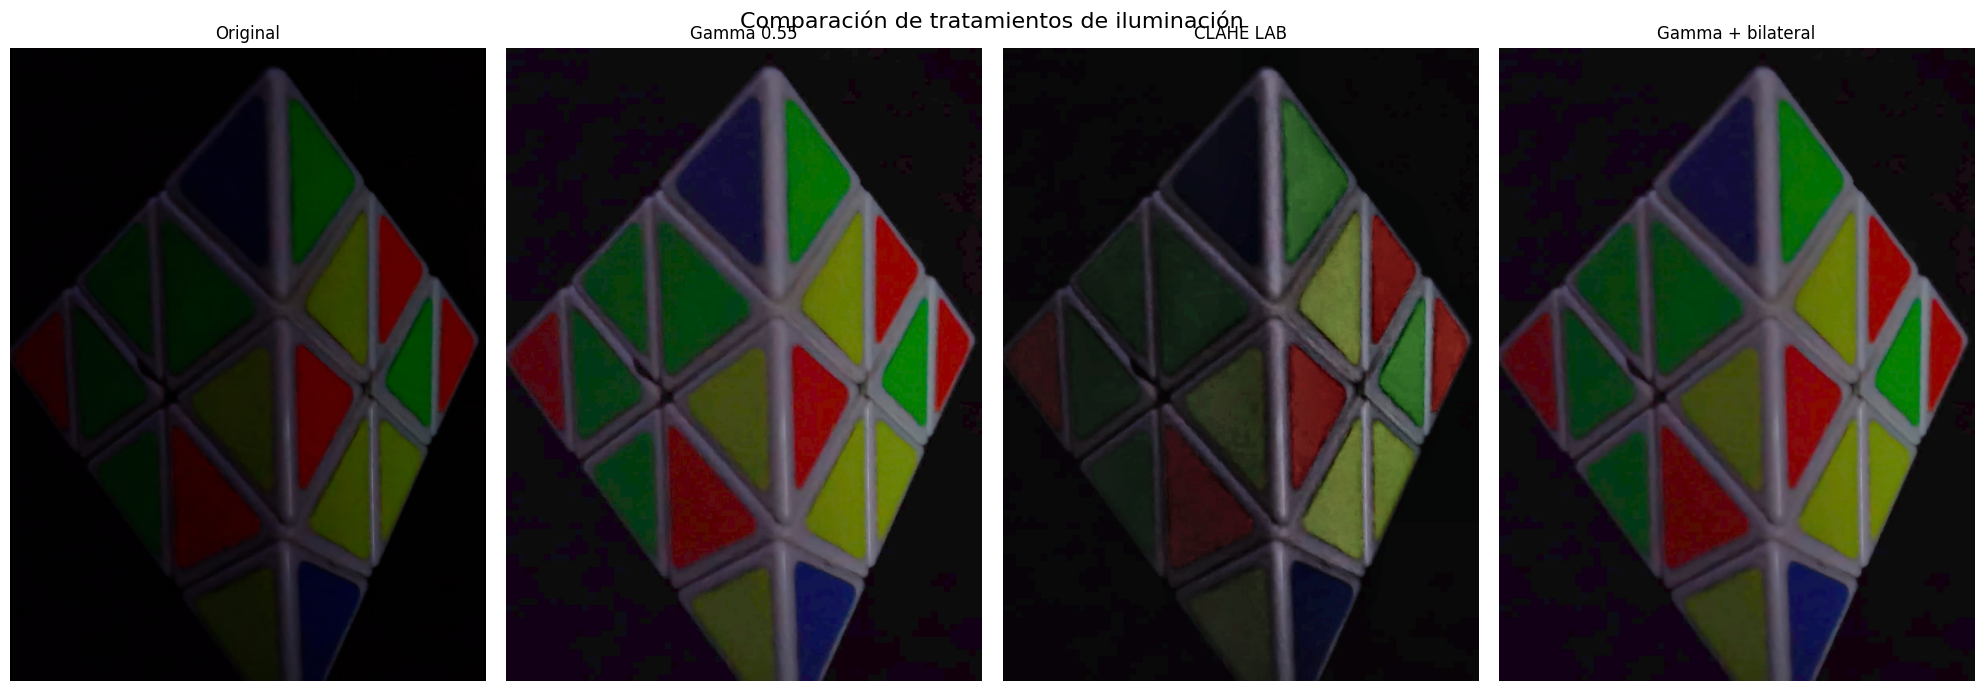

In [18]:

# ============================================================
# BLOQUE 8 - TRATAMIENTOS DE LA IMAGEN SUBEXPUESTA
# ============================================================

# TRATAMIENTO 1: CORRECCIÓN GAMMA

def corregir_gamma(imagen, gamma=0.55):

    valores = np.arange(
        256,
        dtype=np.float32
    ) / 255.0

    tabla = np.clip(
        np.power(valores, gamma) * 255,
        0, 255
    ).astype(np.uint8)

    return cv2.LUT(imagen, tabla)


imagen_gamma = corregir_gamma(
    imagen_original,
    gamma=0.55
)


# TRATAMIENTO 2: CLAHE SOBRE CANAL L DE LAB

def corregir_clahe(imagen):

    lab = cv2.cvtColor(
        imagen,
        cv2.COLOR_BGR2LAB
    )

    l, a, b = cv2.split(lab)

    algoritmo_clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    l_corregido = algoritmo_clahe.apply(l)

    lab_corregido = cv2.merge([
        l_corregido, a, b
    ])

    return cv2.cvtColor(
        lab_corregido,
        cv2.COLOR_LAB2BGR
    )


imagen_clahe = corregir_clahe(
    imagen_original
)


# TRATAMIENTO 3: GAMMA + SUAVIZADO BILATERAL

imagen_gamma_bilateral = cv2.bilateralFilter(
    imagen_gamma,
    d=7,
    sigmaColor=25,
    sigmaSpace=25
)


# GUARDAR TODAS LAS ALTERNATIVAS

TRATAMIENTOS = {
    "Original": imagen_original,
    "Gamma 0.55": imagen_gamma,
    "CLAHE LAB": imagen_clahe,
    "Gamma + bilateral": imagen_gamma_bilateral
}

for i, (nombre, imagen) in enumerate(
    TRATAMIENTOS.items()
):

    archivo_salida = (
        CARPETA_RESULTADOS /
        f"tratamiento_{i:02d}.png"
    )

    cv2.imwrite(
        str(archivo_salida),
        imagen
    )

# MOSTRAR COMPARACIÓN

fig, ejes = plt.subplots(1, 4, figsize=(20, 7))

for eje, (nombre, imagen) in zip(
    ejes, TRATAMIENTOS.items()
):

    eje.imshow(
        cv2.cvtColor(
            imagen,
            cv2.COLOR_BGR2RGB
        )
    )

    eje.set_title(nombre)
    eje.axis("off")

plt.suptitle(
    "Comparación de tratamientos de iluminación",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    CARPETA_RESULTADOS / "06_tratamientos_comparados.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [19]:

# ============================================================
# BLOQUE 9 - EVALUACIÓN DE LOS TRATAMIENTOS
# ============================================================

def evaluar_region(imagen, mascara):

    gris = cv2.cvtColor(
        imagen,
        cv2.COLOR_BGR2GRAY
    )

    region = mascara > 0
    intensidades = gris[region]

    if intensidades.size == 0:
        raise ValueError("La región de interés está vacía.")

    laplaciano = cv2.Laplacian(
        gris,
        cv2.CV_64F
    )

    # Bordes Canny con umbrales constantes
    suavizada = cv2.GaussianBlur(
        gris, (5, 5), 0
    )

    bordes = cv2.Canny(
        suavizada, 40, 110
    )

    hsv = cv2.cvtColor(
        imagen,
        cv2.COLOR_BGR2HSV
    )

    return {
        "Brillo medio": round(
            float(np.mean(intensidades)), 2
        ),
        "Contraste (desv.)": round(
            float(np.std(intensidades)), 2
        ),
        "Píxeles oscuros (%)": round(
            float(np.mean(intensidades <= 20) * 100), 2
        ),
        "Píxeles claros (%)": round(
            float(np.mean(intensidades >= 245) * 100), 2
        ),
        "Varianza Laplaciano": round(
            float(np.var(laplaciano[region])), 2
        ),
        "Bordes Canny (%)": round(
            float(np.mean(bordes[region] > 0) * 100), 2
        ),
        "Saturación HSV media": round(
            float(np.mean(hsv[:, :, 1][region])), 2
        )
    }


evaluaciones = []

for nombre, imagen in TRATAMIENTOS.items():

    resultado = evaluar_region(
        imagen,
        mascara_roi
    )

    evaluaciones.append({
        "Tratamiento": nombre,
        **resultado
    })

tabla_evaluacion = pd.DataFrame(evaluaciones)

display(tabla_evaluacion)

tabla_evaluacion.to_csv(
    CARPETA_RESULTADOS / "07_evaluacion_tratamientos.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Atención: un aumento de la varianza del Laplaciano "
    "también puede estar asociado a amplificación de ruido."
)


,Tratamiento,Brillo medio,Contraste (desv.),Píxeles oscuros (%),Píxeles claros (%),Varianza Laplaciano,Bordes Canny (%),Saturación HSV media
0,Original,22.09,15.31,57.44,0.0,1.75,0.00,169.12
1,Gamma 0.55,57.58,25.97,4.95,0.0,11.74,0.07,142.79
2,CLAHE LAB,41.81,27.95,14.69,0.0,14.59,0.25,95.01
3,Gamma + bilateral,57.58,25.88,4.98,0.0,2.48,0.06,142.34


Atención: un aumento de la varianza del Laplaciano también puede estar asociado a amplificación de ruido.


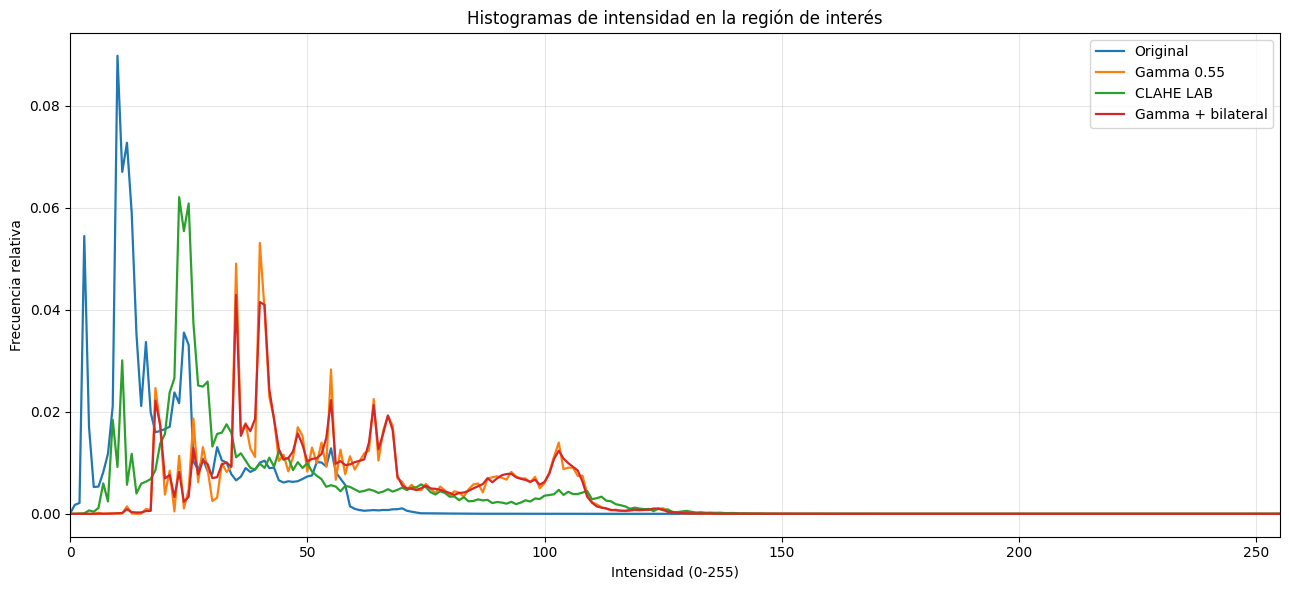

In [20]:

# ============================================================
# BLOQUE 10 - HISTOGRAMAS DE LOS TRATAMIENTOS
# ============================================================

plt.figure(figsize=(13, 6))

region = mascara_roi > 0

for nombre, imagen in TRATAMIENTOS.items():

    gris = cv2.cvtColor(
        imagen,
        cv2.COLOR_BGR2GRAY
    )

    pixeles = gris[region]

    histograma, _ = np.histogram(
        pixeles,
        bins=256,
        range=(0, 256)
    )

    histograma = histograma / histograma.sum()

    plt.plot(
        np.arange(256),
        histograma,
        label=nombre,
        linewidth=1.6
    )

plt.title(
    "Histogramas de intensidad en la región de interés"
)

plt.xlabel("Intensidad (0-255)")
plt.ylabel("Frecuencia relativa")
plt.xlim(0, 255)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    CARPETA_RESULTADOS / "08_histogramas_tratamientos.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


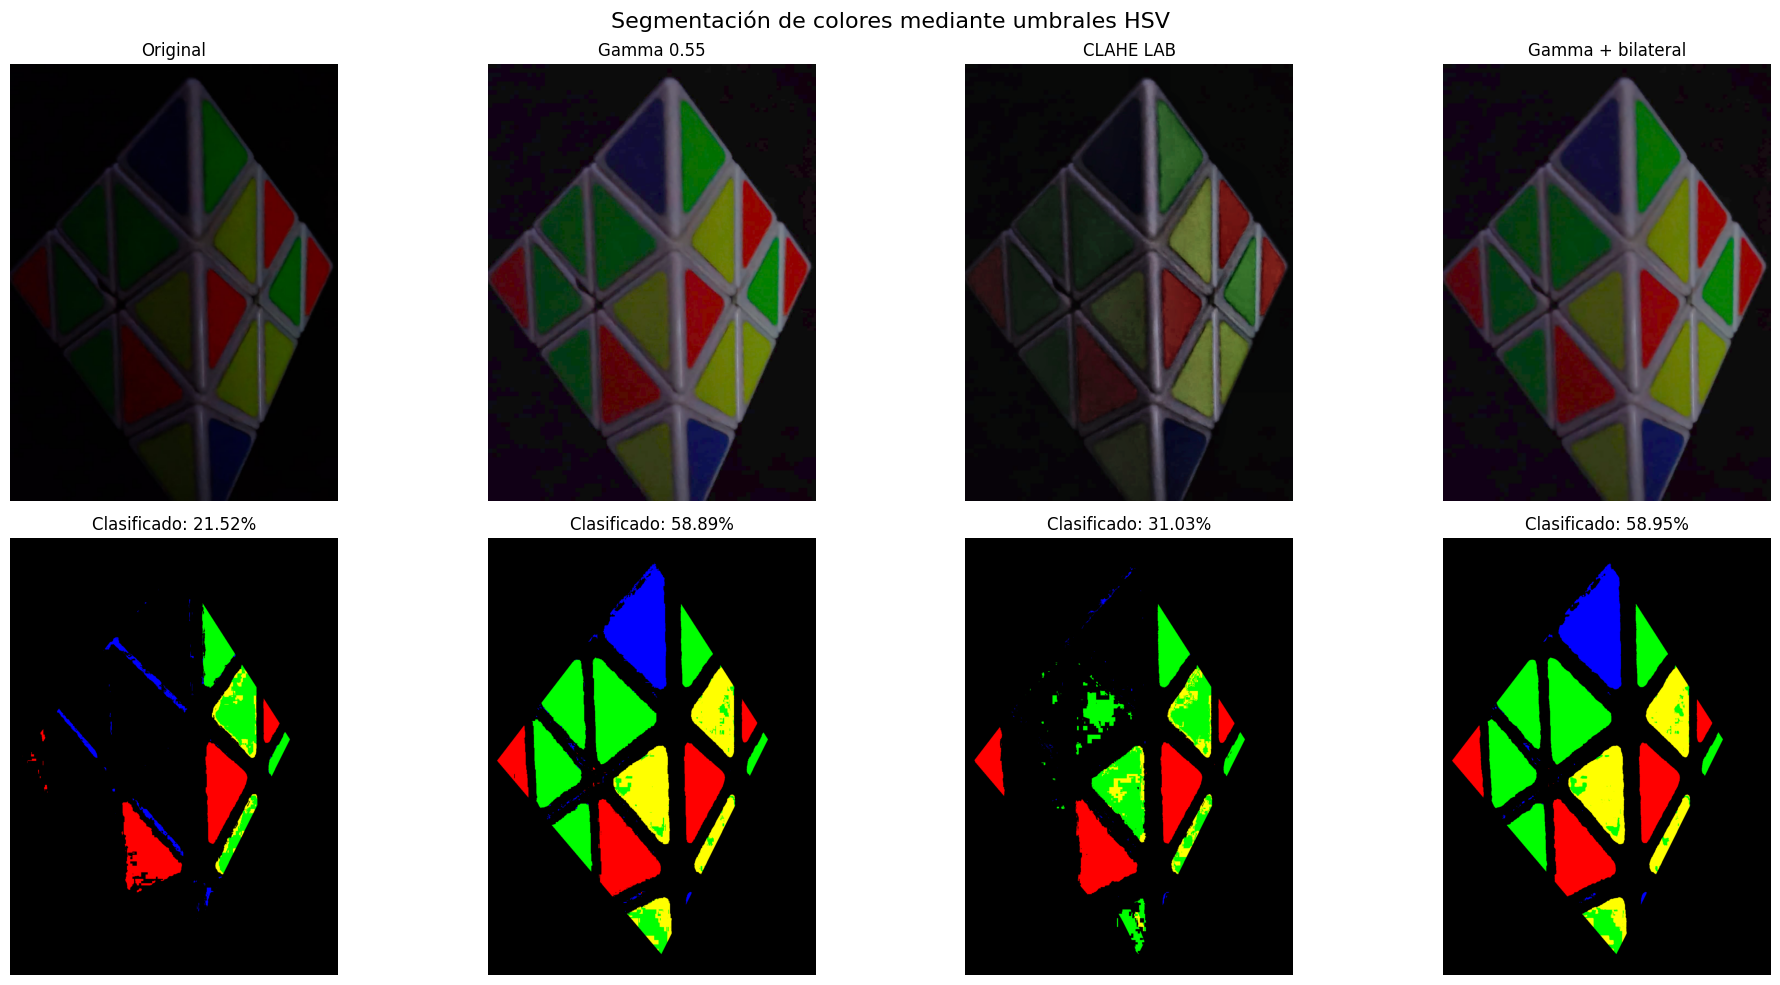

,Tratamiento,Rojo,Verde,Amarillo,Azul,Total clasificados,Porcentaje clasificado
0,Original,73998,56989,10187,13566,154740,21.52
1,Gamma 0.55,98109,172726,88406,64145,423386,58.89
2,CLAHE LAB,92690,106258,22454,1668,223070,31.03
3,Gamma + bilateral,98481,172409,88968,63915,423773,58.95


El porcentaje clasificado representa cobertura de los umbrales HSV, no precisión de clasificación.


In [21]:

# ============================================================
# BLOQUE 11 - SEGMENTACIÓN DE COLORES EN HSV
# ============================================================

COLORES_BGR = {
    "Rojo": (0, 0, 255),
    "Verde": (0, 255, 0),
    "Amarillo": (0, 255, 255),
    "Azul": (255, 0, 0)
}

# Umbrales fijos para todos los tratamientos
SATURACION_MINIMA = 80
VALOR_MINIMO = 35

def detectar_colores(imagen, mascara):

    hsv = cv2.cvtColor(
        imagen,
        cv2.COLOR_BGR2HSV
    )

    h, s, v = cv2.split(hsv)

    region_valida = (
        (mascara > 0) &
        (s >= SATURACION_MINIMA) &
        (v >= VALOR_MINIMO)
    )

    rangos = {
        "Rojo": (h <= 10) | (h >= 170),
        "Verde": (h >= 36) & (h <= 85),
        "Amarillo": (h >= 18) & (h <= 35),
        "Azul": (h >= 90) & (h <= 135)
    }

    imagen_segmentada = np.zeros_like(imagen)

    cantidades = {}
    total_region = np.count_nonzero(mascara)

    for color, condicion in rangos.items():

        seleccion = region_valida & condicion

        imagen_segmentada[seleccion] = COLORES_BGR[color]

        cantidades[color] = int(
            np.count_nonzero(seleccion)
        )

    cantidades["Total clasificados"] = sum(
        cantidades.values()
    )

    cantidades["Porcentaje clasificado"] = round(
        cantidades["Total clasificados"] /
        total_region * 100,
        2
    )

    return imagen_segmentada, cantidades


fig, ejes = plt.subplots(2, 4, figsize=(20, 10))

registros_colores = []

for i, (nombre, imagen) in enumerate(
    TRATAMIENTOS.items()
):

    segmentada, cantidades = detectar_colores(
        imagen,
        mascara_roi
    )

    registros_colores.append({
        "Tratamiento": nombre,
        **cantidades
    })

    ejes[0, i].imshow(
        cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
    )
    ejes[0, i].set_title(nombre)
    ejes[0, i].axis("off")

    ejes[1, i].imshow(
        cv2.cvtColor(segmentada, cv2.COLOR_BGR2RGB)
    )
    ejes[1, i].set_title(
        f"Clasificado: {cantidades['Porcentaje clasificado']}%"
    )
    ejes[1, i].axis("off")

    cv2.imwrite(
        str(
            CARPETA_RESULTADOS /
            f"segmentacion_{i:02d}.png"
        ),
        segmentada
    )

plt.suptitle(
    "Segmentación de colores mediante umbrales HSV",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    CARPETA_RESULTADOS / "09_comparacion_colores.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

tabla_colores = pd.DataFrame(registros_colores)

display(tabla_colores)

tabla_colores.to_csv(
    CARPETA_RESULTADOS / "09_metricas_colores.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "El porcentaje clasificado representa cobertura de "
    "los umbrales HSV, no precisión de clasificación."
)


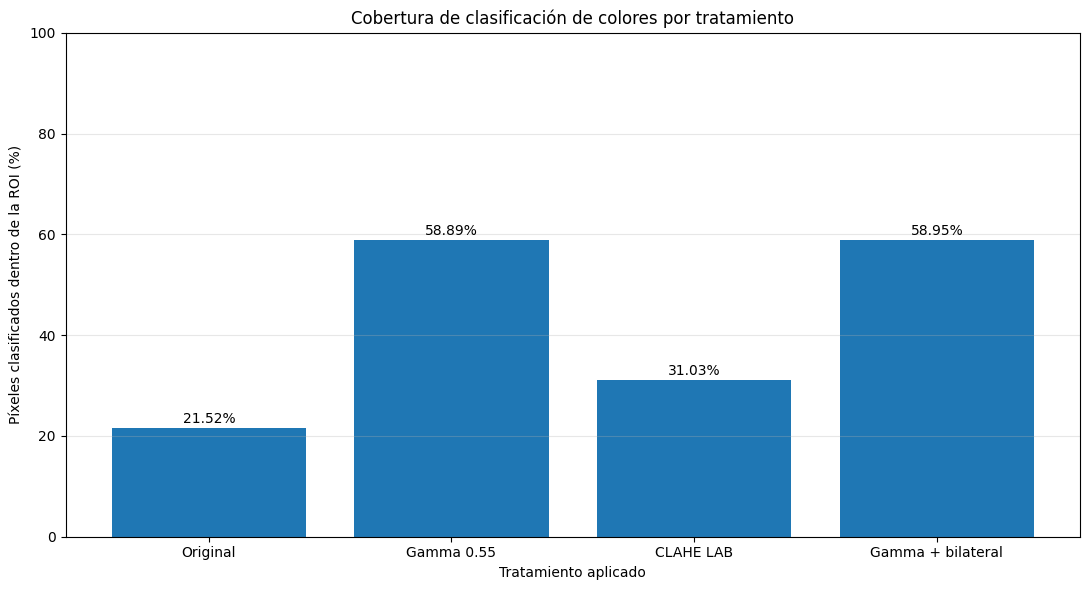

In [22]:

# ============================================================
# BLOQUE 12 - COMPARACIÓN DE COBERTURA HSV
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    tabla_colores["Tratamiento"],
    tabla_colores["Porcentaje clasificado"]
)

plt.title(
    "Cobertura de clasificación de colores por tratamiento"
)

plt.xlabel("Tratamiento aplicado")
plt.ylabel("Píxeles clasificados dentro de la ROI (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

for i, valor in enumerate(
    tabla_colores["Porcentaje clasificado"]
):
    plt.text(
        i,
        valor + 1,
        f"{valor:.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    CARPETA_RESULTADOS / "10_cobertura_colores.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [23]:

# ============================================================
# BLOQUE 13 - VERIFICACIÓN FINAL DE RESULTADOS
# ============================================================

print("=" * 65)
print("PROYECTO: ANÁLISIS DE CALIDAD DE IMÁGENES DEL PYRAMINX")
print("=" * 65)

print("\nIMÁGENES ORIGINALES:")
for condicion, datos in FOTOS.items():
    print(f" - {condicion}: {datos['ruta'].name}")

print("\nARCHIVOS DE RESULTADOS:")

archivos_resultados = sorted(
    CARPETA_RESULTADOS.glob("*")
)

for i, archivo in enumerate(archivos_resultados, 1):
    print(f"{i:02d}. {archivo.name}")

print("\nTOTAL DE ARCHIVOS:", len(archivos_resultados))

print("\nDIAGNÓSTICO GENERAL:")
display(tabla_diagnostico)

print("\nEVALUACIÓN DE TRATAMIENTOS:")
display(tabla_evaluacion)

print("\nSEGMENTACIÓN DE COLORES:")
display(tabla_colores)

print("\nCarpeta:", CARPETA_RESULTADOS)

print("\nPROCESAMIENTO FINALIZADO.")
print(
    "Pendiente: interpretar resultados, verificar limitaciones "
    "y seleccionar el tratamiento más adecuado."
)


PROYECTO: ANÁLISIS DE CALIDAD DE IMÁGENES DEL PYRAMINX

IMÁGENES ORIGINALES:
 - Movimiento: WhatsApp-Image-2026-10-12-at-10.34.26-PM.png
 - Sobreexposición: WhatsApp-Image-2026-10-12-at-10.34.33-PM-_2_.png
 - Subexposición: WhatsApp-Image-2026-10-12-at-10.34.33-PM.png
 - Referencia: WhatsApp-Image-2026-10-12-at-10.34.33-PM-_1_.png
 - Desenfoque: WhatsApp-Image-2026-10-12-at-10.37.28-PM.png

ARCHIVOS DE RESULTADOS:
01. 01_imagenes_originales.png
02. 02_diagnostico.csv
03. 03_histogramas_originales.png
04. 04_comparacion_bordes.png
05. 04_metricas_bordes.csv
06. 05_region_interes.png
07. 06_tratamientos_comparados.png
08. 07_evaluacion_tratamientos.csv
09. 08_histogramas_tratamientos.png
10. 09_comparacion_colores.png
11. 09_metricas_colores.csv
12. 10_cobertura_colores.png
13. bordes_01.png
14. bordes_02.png
15. bordes_03.png
16. bordes_04.png
17. bordes_05.png
18. segmentacion_00.png
19. segmentacion_01.png
20. segmentacion_02.png
21. segmentacion_03.png
22. tratamiento_00.png
23. trat

,Condición,Archivo,Brillo medio,Contraste (desv. estándar),Píxeles oscuros (%),Píxeles claros (%),Varianza del Laplaciano,Entropía (bits)
0,Movimiento,WhatsApp-Image-2026-10-12-at-10.34.26-PM.png,155.17,25.42,0.00,0.06,8.58,6.383
1,Sobreexposición,WhatsApp-Image-2026-10-12-at-10.34.33-PM-_2_.png,244.24,12.78,0.00,69.33,1.80,4.713
2,Subexposición,WhatsApp-Image-2026-10-12-at-10.34.33-PM.png,13.95,17.43,73.55,0.00,1.25,4.167
3,Referencia,WhatsApp-Image-2026-10-12-at-10.34.33-PM-_1_.png,122.11,30.90,0.00,0.07,600.20,6.523
4,Desenfoque,WhatsApp-Image-2026-10-12-at-10.37.28-PM.png,153.57,42.77,0.00,0.00,1.15,7.000



EVALUACIÓN DE TRATAMIENTOS:


,Tratamiento,Brillo medio,Contraste (desv.),Píxeles oscuros (%),Píxeles claros (%),Varianza Laplaciano,Bordes Canny (%),Saturación HSV media
0,Original,22.09,15.31,57.44,0.0,1.75,0.00,169.12
1,Gamma 0.55,57.58,25.97,4.95,0.0,11.74,0.07,142.79
2,CLAHE LAB,41.81,27.95,14.69,0.0,14.59,0.25,95.01
3,Gamma + bilateral,57.58,25.88,4.98,0.0,2.48,0.06,142.34



SEGMENTACIÓN DE COLORES:


,Tratamiento,Rojo,Verde,Amarillo,Azul,Total clasificados,Porcentaje clasificado
0,Original,73998,56989,10187,13566,154740,21.52
1,Gamma 0.55,98109,172726,88406,64145,423386,58.89
2,CLAHE LAB,92690,106258,22454,1668,223070,31.03
3,Gamma + bilateral,98481,172409,88968,63915,423773,58.95



Carpeta: /content/Proyecto_Pyraminx/resultados

PROCESAMIENTO FINALIZADO.
Pendiente: interpretar resultados, verificar limitaciones y seleccionar el tratamiento más adecuado.


In [24]:

# ============================================================
# BLOQUE 14 - RESPALDAR EL PROYECTO EN GOOGLE DRIVE
# ============================================================

from google.colab import drive
import shutil

drive.mount("/content/drive")

DESTINO_DRIVE = Path(
    "/content/drive/MyDrive/Proyecto_Pyraminx"
)

DESTINO_DRIVE.mkdir(
    parents=True,
    exist_ok=True
)

shutil.copytree(
    CARPETA_IMAGENES,
    DESTINO_DRIVE / "imagenes",
    dirs_exist_ok=True
)

shutil.copytree(
    CARPETA_RESULTADOS,
    DESTINO_DRIVE / "resultados",
    dirs_exist_ok=True
)

print("Respaldo completado.")
print("Ubicación:", DESTINO_DRIVE)


MessageError: Error: credential propagation was unsuccessful